# TP3 ► Extraction, classification et fusion de caracteristiques

- **Descripteurs:** Hu, LBP, HOG et SURF
- **Dataset:** Flowers Recognition (suite du TP2)

# 1. Objectifs du TP

L’objectif de ce TP est d'etudier plusieurs methodes classiques d’extraction de caracteristiques pour la reconnaissance des formes et d’evaluer leur capacite a representer et classifier des images. Les descripteurs etudies sont :

- les moments invariants de Hu;
- le descripteur LBP (Local Binary Pattern);
- le descripteur HOG (Histogram of Oriented Gradients);
- le descripteur SURF (Speeded-Up Robust Feature)

Les caracteristiques extraites seront ensuite utilisees comme entree d’un perceptron multicouche (Multi-Layer Perceptron, MLP). Ce TP s’appuie directement sur le travail du TP2 : le split (Train / Validation / Test) a ete construit, verifie et sauvegarde dans `data/split`. Il sera recharge ici sans etre recalcule. A l’issue de ce TP, l’etudiant sera capable de :

- recharger un split sauvegarde et l’utiliser pour l’extraction de caracteristiques;
- extraire des caracteristiques a partir d’images couleur de tailles variables;
- comprendre les differences entre descripteurs globaux, locaux et bases sur les gradients;
- transformer une image en vecteur de caracteristiques;
- entraıner un MLP pour chaque type de descripteur;
- evaluer les performances de chaque representation;
- fusionner plusieurs vecteurs de caract´eristiques;
- entraıner un nouveau MLP a partir des caracteristiques fusionnees;
- comparer les performances avant et apres fusion

# 2. Contexte et problematique

En reconnaissance des formes, une image brute n’est generalement pas directement utilisee par un classifieur classique. Elle est d’abord transformee en une representation numerique appelee vecteur de caracteristiques. La chaıne generale etudiee dans ce TP est

$$ Image \rightarrow Descripteur \rightarrow Caracteristique \rightarrow MLP \rightarrow Classe $$

Plusieurs descripteurs peuvent etre utilises pour representer differentes proprietes d’une meme image. Dans ce TP, on considere notamment :

- HU : forme globale;
- LBP : texture locale;
- HOG : structure des contours et orientations des gradients;
- SURF : caracteristiques locales et points d'interet.

Une deuxieme problematique consiste a determiner si la combinaison de plusieurs representations permet d’ameliorer la classification. On etudiera donc egalement la fusion :

$$ X_{fusion} = [ X_{Hu} | X_{LBP} | X_{HOG} | X_{SURF} ] $$

# 3. Partie 1 : Rechargement du split du TP2

Recharger le `split Train / Validation / Test` produit dans le TP2 et l’utiliser comme reference commune pour tous les descripteurs. Dans ce TP, on utilise le jeu de donnees Flowers Recognition introduit dans le TP2, organise en cinq classes :

Class     | Label
---       | ---
Daisy     |  0
Dandelion |  1
Rose      |  2
Sunflower |  3
Tulip     |  4

In [1]:
import numpy as np
import pandas as pd
import os 

import matplotlib .pyplot as plt
from pathlib import Path
from PIL import Image

In [2]:
SEED = 42
SPLIT_DIR = Path("../datasets/split/flowers/")
CLASS_NAMES = [ 
  "daisy", 
  "dandelion", 
  "rose", 
  "sunflower", 
  "tulip",
]
NUM_CLASSES = len( CLASS_NAMES ) # 5
train_df = pd.read_csv(SPLIT_DIR / "train.csv") 
val_df = pd.read_csv(SPLIT_DIR / "val.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")
print ("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Classes:", CLASS_NAMES)

Train: 3023
Validation: 648
Test: 648
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


## 3.2 Chargement et redimensionnement des images

Les images du dataset Flowers Recognition sont en couleur et de tailles variables. Pour pouvoir comparer les descripteurs, on les redimensionne à une taille fixe :

$$128 \times 128.$$

Le redimensionnement est appliqué de la même façon aux trois ensembles.

> **Prérequis :** cette cellule utilise `np`, `Image`, `train_df`, `val_df` et `test_df` définis en 3.1 (chargement du split sauvegardé).

In [3]:
IMG_SIZE = (128, 128)

def load_image(path, size=IMG_SIZE):
    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize(size)
        return np.array(img)


def load_images(df):
    X = np.array([
        load_image(p)
        for p in df["filepath"]
    ])
    y = df["label"].to_numpy()
    return X, y


X_train, y_train = load_images(train_df)
X_val, y_val = load_images(val_df)
X_test, y_test = load_images(test_df)

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

X_train : (3023, 128, 128, 3)
X_val   : (648, 128, 128, 3)
X_test  : (648, 128, 128, 3)


Le redimensionnement est une étape de prétraitement **déterministe** : elle ne dépend d'aucune statistique apprise et peut donc être appliquée indépendamment à chacun des trois ensembles, sans risque de fuite de données.

### Dépendances

Les parties suivantes utilisent OpenCV, scikit-image, Mahotas (SURF) et PyTorch.

In [4]:
%pip install -q opencv-python scikit-image mahotas torch scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 4. Partie 2 : Extraction des caractéristiques de Hu

**Objectif :** extraire une représentation compacte de la forme globale des objets présents dans les images.

Les moments invariants de Hu permettent de représenter une forme par sept valeurs :

$$x_{Hu} = [\phi_1, \phi_2, \ldots, \phi_7] \in \mathbb{R}^7$$

### 4.1 Extraction

In [5]:
import cv2

def extract_hu(image):

    # Passage en niveaux de gris
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Binarisation (Otsu)
    _, binary = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    moments = cv2.moments(binary)

    hu = cv2.HuMoments(moments).flatten()

    # Transformation logarithmique
    hu = -np.sign(hu) * np.log10(
        np.abs(hu) + 1e-30
    )

    return hu

### 4.2 Construction des matrices de caractéristiques

In [6]:
X_hu_train = np.array([
    extract_hu(img) for img in X_train
])

X_hu_val = np.array([
    extract_hu(img) for img in X_val
])

X_hu_test = np.array([
    extract_hu(img) for img in X_test
])

print(X_hu_train.shape)

(3023, 7)


La dimension obtenue doit être $X_{Hu} \in \mathbb{R}^{N \times 7}$.

## 5. Partie 3 : Extraction des caractéristiques LBP

**Objectif :** représenter la texture locale des images à l'aide du descripteur LBP (Local Binary Pattern).

Pour chaque pixel central, les valeurs de ses voisins sont comparées à la valeur centrale. On utilise $P = 8$ voisins et un rayon $R = 1$.

Pour le LBP uniforme, les motifs sont regroupés en 10 catégories. Chaque image est donc représentée par un histogramme :

$$x_{LBP} \in \mathbb{R}^{10}$$

### 5.1 Extraction

In [7]:
from skimage.feature import local_binary_pattern

def extract_lbp(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    P = 8
    R = 1

    lbp = local_binary_pattern(
        gray,
        P,
        R,
        method="uniform"
    )

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(P + 3),
        range=(0, P + 2)
    )

    hist = hist.astype(np.float32)

    hist /= (hist.sum() + 1e-8)

    return hist

### 5.2 Construction des matrices

In [8]:
X_lbp_train = np.array([
    extract_lbp(img) for img in X_train
])

X_lbp_val = np.array([
    extract_lbp(img) for img in X_val
])

X_lbp_test = np.array([
    extract_lbp(img) for img in X_test
])

print(X_lbp_train.shape)

(3023, 10)


On obtient $X_{LBP} \in \mathbb{R}^{N \times 10}$.

## 6. Partie 4 : Extraction des caractéristiques HOG

**Objectif :** représenter la structure des contours et les orientations des gradients présents dans les images.

Le descripteur HOG est basé sur les gradients de l'image. Pour chaque pixel, $G_x$ et $G_y$ sont calculés, puis :

$$M = \sqrt{G_x^2 + G_y^2} \qquad \theta = \arctan\left(\frac{G_y}{G_x}\right)$$

Les orientations sont ensuite regroupées dans des histogrammes. On utilise :

- des cellules de taille $8 \times 8$ ;
- des blocs de $2 \times 2$ cellules ;
- 9 orientations.

Comme les images ont été redimensionnées à $128 \times 128$, la dimension du vecteur HOG est fixe et déterminée automatiquement.

### 6.1 Extraction

In [9]:
from skimage.feature import hog

def extract_hog(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features.astype(np.float32)

In [10]:
X_hog_train = np.array([
    extract_hog(img) for img in X_train
])

X_hog_val = np.array([
    extract_hog(img) for img in X_val
])

X_hog_test = np.array([
    extract_hog(img) for img in X_test
])

print(X_hog_train.shape)

(3023, 8100)


La dimension du vecteur HOG dépend des paramètres utilisés. Elle doit être déterminée automatiquement par le programme.

In [11]:
D_HOG = X_hog_train.shape[1]
print("D_HOG =", D_HOG)

D_HOG = 8100


## 7. Partie 5 : Extraction des caractéristiques SURF

**Objectif :** détecter des points d'intérêt locaux et construire une représentation compacte des caractéristiques locales.

SURF (Speeded-Up Robust Features) permet de détecter des points d'intérêt dans l'image et de calculer un descripteur pour chaque point. Un descripteur SURF classique possède une dimension de 64.

Une image peut posséder un nombre variable de points d'intérêt : $N_i \times 64$. Les descripteurs SURF ne possèdent donc pas directement une dimension fixe pour toutes les images.

### 7.1 Détection avec Mahotas

In [12]:
import mahotas
from mahotas.features import surf

def extract_surf(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = gray.astype(np.uint8)

    descriptors = surf.surf(
        gray,
        descriptor_only=True
    )

    return descriptors

### 7.2 Problème de dimension variable

Pour une image donnée, $D_i \in \mathbb{R}^{N_i \times 64}$, or un MLP nécessite un vecteur de dimension fixe. Il faut donc transformer les descripteurs locaux en une représentation de taille fixe : on utilise une représentation **Bag of Visual Words (BoVW)**.

`SURF → K-Means → K mots visuels → Histogramme`

On pose par exemple $K = 50$. Ainsi, chaque image sera représentée par $x_{SURF} \in \mathbb{R}^{50}$.

Le vocabulaire visuel est appris **uniquement sur les descripteurs SURF du Train**. Validation et Test sont ensuite transformés avec ce vocabulaire.

### 7.3 Construction du vocabulaire visuel

*(Les descripteurs de chaque image sont calculés une seule fois puis réutilisés pour le vocabulaire et pour l'histogramme BoVW, afin d'éviter de refaire l'extraction SURF.)*

In [13]:
# Extraction SURF une seule fois par image
desc_train = [extract_surf(img) for img in X_train]
desc_val = [extract_surf(img) for img in X_val]
desc_test = [extract_surf(img) for img in X_test]

print("Images sans point d'intérêt (train) :",
      sum(d is None or len(d) == 0 for d in desc_train))

Images sans point d'intérêt (train) : 0


In [14]:
from sklearn.cluster import MiniBatchKMeans

all_descriptors = []

for desc in desc_train:

    if desc is not None and len(desc) > 0:
        all_descriptors.append(desc[:, -64:])

all_descriptors = np.vstack(all_descriptors)

print("Descripteurs du Train :", all_descriptors.shape)

K = 50

kmeans = MiniBatchKMeans(
    n_clusters=K,
    random_state=SEED,
    batch_size=2048
)

kmeans.fit(all_descriptors)

Descripteurs du Train : (64300, 64)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.",50
,"batch_size batch_size: int, default=1024Size of the mini batches.For faster computations, you can set `batch_size > 256 * number_of_cores`to enable :ref:`parallelism <lower-level-parallelism-with-openmp>`on all cores... versionchanged:: 1.0 `batch_size` default changed from 100 to 1024.",2048
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization andrandom reassignment. Use an int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:'k-means++' : selects initial cluster centroids using sampling based onan empirical probability distribution of the points' contribution to theoverall inertia. This technique speeds up convergence. The algorithmimplemented is ""greedy k-means++"". It differs from the vanilla k-means++by making several trials at each sampling step and choosing the best centroidamong them.'random': choose `n_clusters` observations (rows) at random from datafor the initial centroids.If an array is passed, it should be of shape (n_clusters, n_features)and gives the initial centers.If a callable is passed, it should take arguments X, n_clusters and arandom state and return an initialization.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=100Maximum number of iterations over the complete dataset beforestopping independently of any early stopping criterion heuristics.",100
,"verbose verbose: int, default=0Verbosity mode.",0
,"compute_labels compute_labels: bool, default=TrueCompute label assignment and inertia for the complete datasetonce the minibatch optimization has converged in fit.",True
,"tol tol: float, default=0.0Control early stopping based on the relative center changes asmeasured by a smoothed, variance-normalized of the mean centersquared position changes. This early stopping heuristics iscloser to the one used for the batch variant of the algorithmsbut induces a slight computational and memory overhead over theinertia heuristic.To disable convergence detection based on normalized centerchange, set tol to 0.0 (default).",0.0
,"max_no_improvement max_no_improvement: int, default=10Control early stopping based on the consecutive number of minibatches that does not yield an improvement on the smoothed inertia.To disable convergence detection based on inertia, setmax_no_improvement to None.",10
,"init_size init_size: int, default=NoneNumber of samples to randomly sample for speeding up theinitialization (sometimes at the expense of accuracy): theonly algorithm is initialized by running a batch KMeans on arandom subset of the data. This needs to be larger than n_clusters.If `None`, the heuristic is `init_size = 3 * batch_size` if`3 * batch_size < n_clusters`, else `init_size = 3 * n_clusters`.",None
,"n_init n_init: 'auto' or int, default=""auto""Number of random initializations that are tried.In contrast to KMeans, the algorithm is only run once, using the best ofthe `n_init` initializations as measured by inertia. Several runs arerecommended for sparse high-dimensional problems (see:ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:3 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'` in version.",'auto'


### 7.4 Construction de l'histogramme BoVW

In [15]:
def surf_bovw_from_desc(desc, kmeans):

    if desc is None or len(desc) == 0:
        return np.zeros(
            kmeans.n_clusters,
            dtype=np.float32
        )

    desc = desc[:, -64:]

    words = kmeans.predict(desc)

    histogram = np.bincount(
        words,
        minlength=kmeans.n_clusters
    )

    histogram = histogram.astype(np.float32)

    histogram /= (histogram.sum() + 1e-8)

    return histogram


def surf_bovw(image, kmeans):
    return surf_bovw_from_desc(extract_surf(image), kmeans)

In [16]:
X_surf_train = np.array([
    surf_bovw_from_desc(d, kmeans) for d in desc_train
])

X_surf_val = np.array([
    surf_bovw_from_desc(d, kmeans) for d in desc_val
])

X_surf_test = np.array([
    surf_bovw_from_desc(d, kmeans) for d in desc_test
])

print(X_surf_train.shape)

(3023, 50)


## 8. Partie 6 : Normalisation des caractéristiques

**Objectif :** mettre les différentes familles de caractéristiques dans des espaces numériques comparables avant l'apprentissage.

On utilise `StandardScaler`. Le scaler est ajusté **uniquement sur les données d'entraînement**. Validation et Test sont uniquement transformés avec le scaler ajusté.

In [17]:
from sklearn.preprocessing import StandardScaler

# --- Hu ---
scaler_hu = StandardScaler()

X_hu_train = scaler_hu.fit_transform(X_hu_train)
X_hu_val = scaler_hu.transform(X_hu_val)
X_hu_test = scaler_hu.transform(X_hu_test)

# --- LBP ---
scaler_lbp = StandardScaler()

X_lbp_train = scaler_lbp.fit_transform(X_lbp_train)
X_lbp_val = scaler_lbp.transform(X_lbp_val)
X_lbp_test = scaler_lbp.transform(X_lbp_test)

# --- HOG ---
scaler_hog = StandardScaler()

X_hog_train = scaler_hog.fit_transform(X_hog_train)
X_hog_val = scaler_hog.transform(X_hog_val)
X_hog_test = scaler_hog.transform(X_hog_test)

# --- SURF (BoVW) ---
scaler_surf = StandardScaler()

X_surf_train = scaler_surf.fit_transform(X_surf_train)
X_surf_val = scaler_surf.transform(X_surf_val)
X_surf_test = scaler_surf.transform(X_surf_test)

print("Moyenne (train) Hu  :", X_hu_train.mean().round(4))
print("Ecart-type (train)  :", X_hu_train.std().round(4))

Moyenne (train) Hu  : 0.0
Ecart-type (train)  : 1.0


> **Attention :** cette cellule ne doit être exécutée **qu'une seule fois** après l'extraction (sinon on re-normalise des données déjà normalisées). En cas de doute, ré-exécuter les parties 4 à 7.

## 9. Partie 7 : Classification avec un MLP

**Objectif :** construire un classifieur MLP indépendant pour chaque descripteur, afin de comparer directement les différentes représentations.

Structure générale : `Features → MLP → 5 classes`

### 9.1 Architectures

| Descripteur | Architecture |
|---|---|
| Hu | 7 → 32 → 16 → 5 |
| LBP | 10 → 32 → 16 → 5 |
| HOG | $D_{HOG}$ → 128 → 64 → 5 |
| SURF-BoVW | 50 → 64 → 32 → 5 |

### 9.2 Implémentation

La classe MLP du sujet utilise des couches cachées fixes (128, 64). Pour respecter les architectures ci-dessus, les dimensions des couches cachées sont ici un paramètre (`hidden_dims`) ; avec `(128, 64)` on retrouve exactement le modèle du sujet.

In [18]:
import torch
import torch.nn as nn

NUM_CLASSES = 5

def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)


class MLP(nn.Module):

    def __init__(self, input_dim, hidden_dims=(128, 64),
                 num_classes=5, dropout=0.2):

        super().__init__()

        layers = []
        prev = input_dim

        for h in hidden_dims:
            layers += [
                nn.Linear(prev, h),
                nn.ReLU(),
                nn.Dropout(dropout)
            ]
            prev = h

        layers.append(nn.Linear(prev, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

### 9.3 Entraînement

On utilise la fonction de perte Cross-Entropy, l'optimiseur Adam, une validation pendant l'entraînement et une évaluation finale sur le jeu de test.

In [19]:
def train_model(model, X_tr, y_tr, X_va, y_va,
                epochs=20, batch_size=64):

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
    y_tr_t = torch.tensor(y_tr, dtype=torch.long)
    X_va_t = torch.tensor(X_va, dtype=torch.float32)
    y_va_t = torch.tensor(y_va, dtype=torch.long)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=1e-3
    )

    n = len(X_tr_t)

    for epoch in range(epochs):

        model.train()
        perm = torch.randperm(n)

        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_tr_t[idx], y_tr_t[idx]

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_va_t)
            val_pred = val_logits.argmax(dim=1)
            val_acc = (
                (val_pred == y_va_t)
                .float().mean().item()
            )

        print(
            f"Epoch {epoch+1:02d} "
            f"- val_acc = {val_acc:.4f}"
        )

    return model

## 10. Partie 8 : Évaluation des descripteurs

**Objectif :** comparer la qualité des différentes représentations. Pour chaque descripteur : Accuracy, Précision, Rappel, F1-score (macro) et matrice de confusion.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_model(model, X_te, y_te):

    model.eval()
    with torch.no_grad():
        X_te_t = torch.tensor(
            X_te, dtype=torch.float32
        )
        logits = model(X_te_t)
        pred = logits.argmax(dim=1).numpy()

    print("Accuracy  :",
          accuracy_score(y_te, pred))
    print("Precision :",
          precision_score(
              y_te, pred,
              average="macro",
              zero_division=0
          ))
    print("Recall    :",
          recall_score(
              y_te, pred,
              average="macro",
              zero_division=0
          ))
    print("F1-score  :",
          f1_score(
              y_te, pred,
              average="macro",
              zero_division=0
          ))
    print("Matrice de confusion :")
    print(confusion_matrix(y_te, pred))

    return pred

Pour remplir les tableaux, on regroupe entraînement, évaluation et stockage des résultats dans une fonction (graine fixée avant chaque modèle pour la reproductibilité).

In [21]:
results = {}   # nom du modèle -> métriques
preds = {}     # nom du modèle -> prédictions sur le test


def run_experiment(name, X_tr, X_va, X_te, hidden_dims):

    print("=" * 60)
    print(name, "| dimension :", X_tr.shape[1])
    print("=" * 60)

    set_seed(SEED)

    model = MLP(
        input_dim=X_tr.shape[1],
        hidden_dims=hidden_dims,
        num_classes=NUM_CLASSES
    )

    model = train_model(
        model, X_tr, y_train, X_va, y_val
    )

    pred = evaluate_model(model, X_te, y_test)

    results[name] = {
        "Dimension": X_tr.shape[1],
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="macro", zero_division=0),
        "Recall": recall_score(
            y_test, pred, average="macro", zero_division=0),
        "F1-score": f1_score(
            y_test, pred, average="macro", zero_division=0),
    }
    preds[name] = pred

    return model

### MLP-Hu

In [22]:
mlp_hu = run_experiment(
    "MLP-Hu",
    X_hu_train, X_hu_val, X_hu_test,
    hidden_dims=(32, 16)
)

MLP-Hu | dimension : 7
Epoch 01 - val_acc = 0.2562
Epoch 02 - val_acc = 0.2562
Epoch 03 - val_acc = 0.2809
Epoch 04 - val_acc = 0.2824
Epoch 05 - val_acc = 0.2917
Epoch 06 - val_acc = 0.2963
Epoch 07 - val_acc = 0.3071
Epoch 08 - val_acc = 0.3086
Epoch 09 - val_acc = 0.3009
Epoch 10 - val_acc = 0.3071
Epoch 11 - val_acc = 0.3009
Epoch 12 - val_acc = 0.3056
Epoch 13 - val_acc = 0.3179
Epoch 14 - val_acc = 0.3117
Epoch 15 - val_acc = 0.3225
Epoch 16 - val_acc = 0.3272
Epoch 17 - val_acc = 0.3287
Epoch 18 - val_acc = 0.3380
Epoch 19 - val_acc = 0.3333
Epoch 20 - val_acc = 0.3349
Accuracy  : 0.30709876543209874
Precision : 0.2847199768216717
Recall    : 0.2649400518038789
F1-score  : 0.19104253250500386
Matrice de confusion :
[[ 2 63  1  2 47]
 [ 3 97  0  3 55]
 [ 2 49  1  2 64]
 [ 1 38  1  5 65]
 [ 1 48  1  3 94]]


### MLP-LBP

In [23]:
mlp_lbp = run_experiment(
    "MLP-LBP",
    X_lbp_train, X_lbp_val, X_lbp_test,
    hidden_dims=(32, 16)
)

MLP-LBP | dimension : 10
Epoch 01 - val_acc = 0.2840
Epoch 02 - val_acc = 0.2870
Epoch 03 - val_acc = 0.2917
Epoch 04 - val_acc = 0.3102
Epoch 05 - val_acc = 0.3333
Epoch 06 - val_acc = 0.3488
Epoch 07 - val_acc = 0.3549
Epoch 08 - val_acc = 0.3765
Epoch 09 - val_acc = 0.4074
Epoch 10 - val_acc = 0.4105
Epoch 11 - val_acc = 0.4213
Epoch 12 - val_acc = 0.4198
Epoch 13 - val_acc = 0.4352
Epoch 14 - val_acc = 0.4228
Epoch 15 - val_acc = 0.4367
Epoch 16 - val_acc = 0.4398
Epoch 17 - val_acc = 0.4414
Epoch 18 - val_acc = 0.4506
Epoch 19 - val_acc = 0.4491
Epoch 20 - val_acc = 0.4552
Accuracy  : 0.42901234567901236
Precision : 0.42862982428199814
Recall    : 0.42096189468848283
F1-score  : 0.41336012365110736
Matrice de confusion :
[[32 29 25 15 14]
 [11 80 16 28 23]
 [10 37 28 25 18]
 [ 4 11 12 63 20]
 [ 6 25 11 30 75]]


### MLP-HOG

In [24]:
mlp_hog = run_experiment(
    "MLP-HOG",
    X_hog_train, X_hog_val, X_hog_test,
    hidden_dims=(128, 64)
)

MLP-HOG | dimension : 8100
Epoch 01 - val_acc = 0.4583
Epoch 02 - val_acc = 0.4429
Epoch 03 - val_acc = 0.4444
Epoch 04 - val_acc = 0.4660
Epoch 05 - val_acc = 0.4429
Epoch 06 - val_acc = 0.4429
Epoch 07 - val_acc = 0.4537
Epoch 08 - val_acc = 0.4475
Epoch 09 - val_acc = 0.4383
Epoch 10 - val_acc = 0.4367
Epoch 11 - val_acc = 0.4275
Epoch 12 - val_acc = 0.4259
Epoch 13 - val_acc = 0.4290
Epoch 14 - val_acc = 0.4167
Epoch 15 - val_acc = 0.4228
Epoch 16 - val_acc = 0.4352
Epoch 17 - val_acc = 0.4429
Epoch 18 - val_acc = 0.4491
Epoch 19 - val_acc = 0.4321
Epoch 20 - val_acc = 0.4537
Accuracy  : 0.41203703703703703
Precision : 0.4057811065705369
Recall    : 0.4028961608396086
F1-score  : 0.40293754903539236
Matrice de confusion :
[[43 20 12 17 23]
 [21 66 22 22 27]
 [18 29 42 14 15]
 [19 32  7 34 18]
 [14 16 11 24 82]]


### MLP-SURF (BoVW)

In [25]:
mlp_surf = run_experiment(
    "MLP-SURF",
    X_surf_train, X_surf_val, X_surf_test,
    hidden_dims=(64, 32)
)

MLP-SURF | dimension : 50
Epoch 01 - val_acc = 0.2855
Epoch 02 - val_acc = 0.3056
Epoch 03 - val_acc = 0.3148
Epoch 04 - val_acc = 0.3318
Epoch 05 - val_acc = 0.3349
Epoch 06 - val_acc = 0.3380
Epoch 07 - val_acc = 0.3410
Epoch 08 - val_acc = 0.3349
Epoch 09 - val_acc = 0.3441
Epoch 10 - val_acc = 0.3580
Epoch 11 - val_acc = 0.3457
Epoch 12 - val_acc = 0.3549
Epoch 13 - val_acc = 0.3519
Epoch 14 - val_acc = 0.3426
Epoch 15 - val_acc = 0.3534
Epoch 16 - val_acc = 0.3503
Epoch 17 - val_acc = 0.3457
Epoch 18 - val_acc = 0.3441
Epoch 19 - val_acc = 0.3488
Epoch 20 - val_acc = 0.3333
Accuracy  : 0.33487654320987653
Precision : 0.31570551307895106
Recall    : 0.32141986376236215
F1-score  : 0.3151330243060808
Matrice de confusion :
[[39 28 13 12 23]
 [21 69 17 18 33]
 [16 29 14 15 44]
 [26 24 12 29 19]
 [20 26 20 15 66]]


Tableau récapitulatif des descripteurs seuls :

In [26]:
single_models = ["MLP-Hu", "MLP-LBP", "MLP-HOG", "MLP-SURF"]

pd.DataFrame(results).T.loc[single_models].round(4)

,Dimension,Accuracy,Precision,Recall,F1-score
MLP-Hu,7.0,0.3071,0.2847,0.2649,0.1910
MLP-LBP,10.0,0.4290,0.4286,0.4210,0.4134
MLP-HOG,8100.0,0.4120,0.4058,0.4029,0.4029
MLP-SURF,50.0,0.3349,0.3157,0.3214,0.3151


### 10.1 Questions

1. Quel descripteur donne les meilleures performances ?
2. Quel descripteur est le plus compact ?
3. Pourquoi Hu est-il adapté à la représentation de la forme globale ?
4. Pourquoi LBP est-il particulièrement adapté à la texture ?
5. Quelle information HOG apporte-t-il ?
6. Pourquoi SURF produit-il naturellement un nombre variable de descripteurs ?
7. Pourquoi utilise-t-on BoVW avant le MLP pour SURF ?

**Réponses :**

*(à compléter)*

## 11. Partie 9 : Fusion de caractéristiques

**Objectif :** combiner les informations complémentaires fournies par les différents descripteurs et entraîner un nouveau MLP.

La fusion est réalisée au niveau des caractéristiques (*feature-level fusion*) :

$$X_{fusion} = [X_{Hu} \mid X_{LBP} \mid X_{HOG} \mid X_{SURF}]$$

Avec des cellules $8 \times 8$ sur une image $128 \times 128$ et des blocs $2 \times 2$, on obtient $D_{HOG} = 8100$. La dimension de fusion est alors :

$$D_{fusion} = 7 + 10 + 8100 + 50 = 8167.$$

Les caractéristiques doivent être normalisées **avant** la concaténation (c'est le cas, Partie 6), afin d'éviter qu'une famille de caractéristiques domine les autres uniquement à cause de son échelle numérique.

### 11.1 Concaténation

In [27]:
X_fusion_train = np.concatenate(
    [
        X_hu_train,
        X_lbp_train,
        X_hog_train,
        X_surf_train
    ],
    axis=1
)

X_fusion_val = np.concatenate(
    [
        X_hu_val,
        X_lbp_val,
        X_hog_val,
        X_surf_val
    ],
    axis=1
)

X_fusion_test = np.concatenate(
    [
        X_hu_test,
        X_lbp_test,
        X_hog_test,
        X_surf_test
    ],
    axis=1
)

print("Dimension fusion :", X_fusion_train.shape)
print("Dimension attendue :", 7 + 10 + D_HOG + 50)

Dimension fusion : (3023, 8167)
Dimension attendue : 8167


## 12. Partie 10 : MLP sur les caractéristiques fusionnées

Architecture : $D_{fusion} \rightarrow 256 \rightarrow 128 \rightarrow 64 \rightarrow 5$.

Le MLP de fusion est un **nouveau modèle**. Il ne s'agit pas de fusionner les sorties des quatre MLP précédents : les quatre vecteurs sont concaténés avant l'apprentissage.

### 12.1 Entraînement

In [28]:
fusion_model = run_experiment(
    "MLP-Fusion complet",
    X_fusion_train, X_fusion_val, X_fusion_test,
    hidden_dims=(256, 128, 64)
)

MLP-Fusion complet | dimension : 8167
Epoch 01 - val_acc = 0.4583
Epoch 02 - val_acc = 0.4861
Epoch 03 - val_acc = 0.4460
Epoch 04 - val_acc = 0.4475
Epoch 05 - val_acc = 0.4290
Epoch 06 - val_acc = 0.4537
Epoch 07 - val_acc = 0.4506
Epoch 08 - val_acc = 0.4475
Epoch 09 - val_acc = 0.4722
Epoch 10 - val_acc = 0.4645
Epoch 11 - val_acc = 0.4475
Epoch 12 - val_acc = 0.4444
Epoch 13 - val_acc = 0.4769
Epoch 14 - val_acc = 0.4676
Epoch 15 - val_acc = 0.4707
Epoch 16 - val_acc = 0.4537
Epoch 17 - val_acc = 0.4552
Epoch 18 - val_acc = 0.4583
Epoch 19 - val_acc = 0.4522
Epoch 20 - val_acc = 0.4414
Accuracy  : 0.4398148148148148
Precision : 0.42847287035153725
Recall    : 0.4280597984216087
F1-score  : 0.42580769644790245
Matrice de confusion :
[[41 22 17 11 24]
 [15 73 25 18 27]
 [20 18 51  9 20]
 [16 28 14 32 20]
 [ 9 15 19 16 88]]


## 13. Partie 11 : Étude de la fusion progressive

**Objectif :** étudier l'influence de l'ajout progressif des différents descripteurs.

$$X_1 = X_{Hu},\quad X_2 = [X_{Hu}|X_{LBP}],\quad X_3 = [X_{Hu}|X_{LBP}|X_{HOG}],\quad X_4 = [X_{Hu}|X_{LBP}|X_{HOG}|X_{SURF}]$$

Pour chaque représentation, un nouveau MLP est entraîné. Pour que la comparaison ne dépende que des caractéristiques, **tous les modèles de cette partie utilisent la même architecture** (256 → 128 → 64 → 5).

In [29]:
blocks = {
    "hu":   (X_hu_train,   X_hu_val,   X_hu_test),
    "lbp":  (X_lbp_train,  X_lbp_val,  X_lbp_test),
    "hog":  (X_hog_train,  X_hog_val,  X_hog_test),
    "surf": (X_surf_train, X_surf_val, X_surf_test),
}

configs = [
    ("Hu",                      ["hu"]),
    ("Hu + LBP",                ["hu", "lbp"]),
    ("Hu + LBP + HOG",          ["hu", "lbp", "hog"]),
    ("Hu + LBP + HOG + SURF",   ["hu", "lbp", "hog", "surf"]),
]

for label, keys in configs:

    Xtr = np.concatenate([blocks[k][0] for k in keys], axis=1)
    Xva = np.concatenate([blocks[k][1] for k in keys], axis=1)
    Xte = np.concatenate([blocks[k][2] for k in keys], axis=1)

    run_experiment(
        f"Prog: {label}",
        Xtr, Xva, Xte,
        hidden_dims=(256, 128, 64)
    )

Prog: Hu | dimension : 7
Epoch 01 - val_acc = 0.3102
Epoch 02 - val_acc = 0.3287
Epoch 03 - val_acc = 0.3364
Epoch 04 - val_acc = 0.3472
Epoch 05 - val_acc = 0.3488
Epoch 06 - val_acc = 0.3349
Epoch 07 - val_acc = 0.3519
Epoch 08 - val_acc = 0.3410
Epoch 09 - val_acc = 0.3333
Epoch 10 - val_acc = 0.3364
Epoch 11 - val_acc = 0.3287
Epoch 12 - val_acc = 0.3380
Epoch 13 - val_acc = 0.3210
Epoch 14 - val_acc = 0.3241
Epoch 15 - val_acc = 0.3133
Epoch 16 - val_acc = 0.3380
Epoch 17 - val_acc = 0.3194
Epoch 18 - val_acc = 0.3256
Epoch 19 - val_acc = 0.3210
Epoch 20 - val_acc = 0.3086
Accuracy  : 0.32098765432098764
Precision : 0.2987990968201856
Recall    : 0.29786308269751566
F1-score  : 0.28182123449301955
Matrice de confusion :
[[24 34  5 12 40]
 [16 77  8 15 42]
 [16 30  9 13 50]
 [11 22  8 22 47]
 [12 29 11 19 76]]
Prog: Hu + LBP | dimension : 17
Epoch 01 - val_acc = 0.3889
Epoch 02 - val_acc = 0.4074
Epoch 03 - val_acc = 0.4321
Epoch 04 - val_acc = 0.4244
Epoch 05 - val_acc = 0.4321
Ep

In [30]:
prog_names = [f"Prog: {label}" for label, _ in configs]

prog_table = pd.DataFrame(results).T.loc[prog_names].round(4)
prog_table.index = [n.replace("Prog: ", "") for n in prog_table.index]
prog_table

,Dimension,Accuracy,Precision,Recall,F1-score
Hu,7.0,0.3210,0.2988,0.2979,0.2818
Hu + LBP,17.0,0.4630,0.4601,0.4591,0.4554
Hu + LBP + HOG,8117.0,0.4259,0.4194,0.4158,0.4161
Hu + LBP + HOG + SURF,8167.0,0.4398,0.4285,0.4281,0.4258


### 13.1 Questions

1. L'ajout de LBP améliore-t-il les performances ?
2. L'ajout de HOG améliore-t-il les performances ?
3. L'ajout de SURF améliore-t-il les performances ?
4. La combinaison de tous les descripteurs est-elle nécessairement meilleure ?
5. Que peut-on conclure sur la complémentarité des descripteurs ?
6. Une augmentation de la dimension des caractéristiques garantit-elle une meilleure classification ?

**Réponses :**

*(à compléter)*

## 14. Partie 12 : Comparaison finale

**Objectif :** comparer les performances de tous les modèles construits dans le TP.

In [31]:
final_models = {
    "MLP-Hu":              "MLP-Hu",
    "MLP-LBP":             "MLP-LBP",
    "MLP-HOG":             "MLP-HOG",
    "MLP-SURF":            "MLP-SURF",
    "MLP-Hu+LBP":          "Prog: Hu + LBP",
    "MLP-Hu+LBP+HOG":      "Prog: Hu + LBP + HOG",
    "MLP-Fusion complet":  "MLP-Fusion complet",
}

final_table = pd.DataFrame({
    display: results[key]
    for display, key in final_models.items()
}).T

final_table["Dimension"] = final_table["Dimension"].astype(int)
final_table.round(4)

,Dimension,Accuracy,Precision,Recall,F1-score
MLP-Hu,7,0.3071,0.2847,0.2649,0.1910
MLP-LBP,10,0.4290,0.4286,0.4210,0.4134
MLP-HOG,8100,0.4120,0.4058,0.4029,0.4029
MLP-SURF,50,0.3349,0.3157,0.3214,0.3151
MLP-Hu+LBP,17,0.4630,0.4601,0.4591,0.4554
MLP-Hu+LBP+HOG,8117,0.4259,0.4194,0.4158,0.4161
MLP-Fusion complet,8167,0.4398,0.4285,0.4281,0.4258


Matrices de confusion de tous les modèles (jeu de test) :

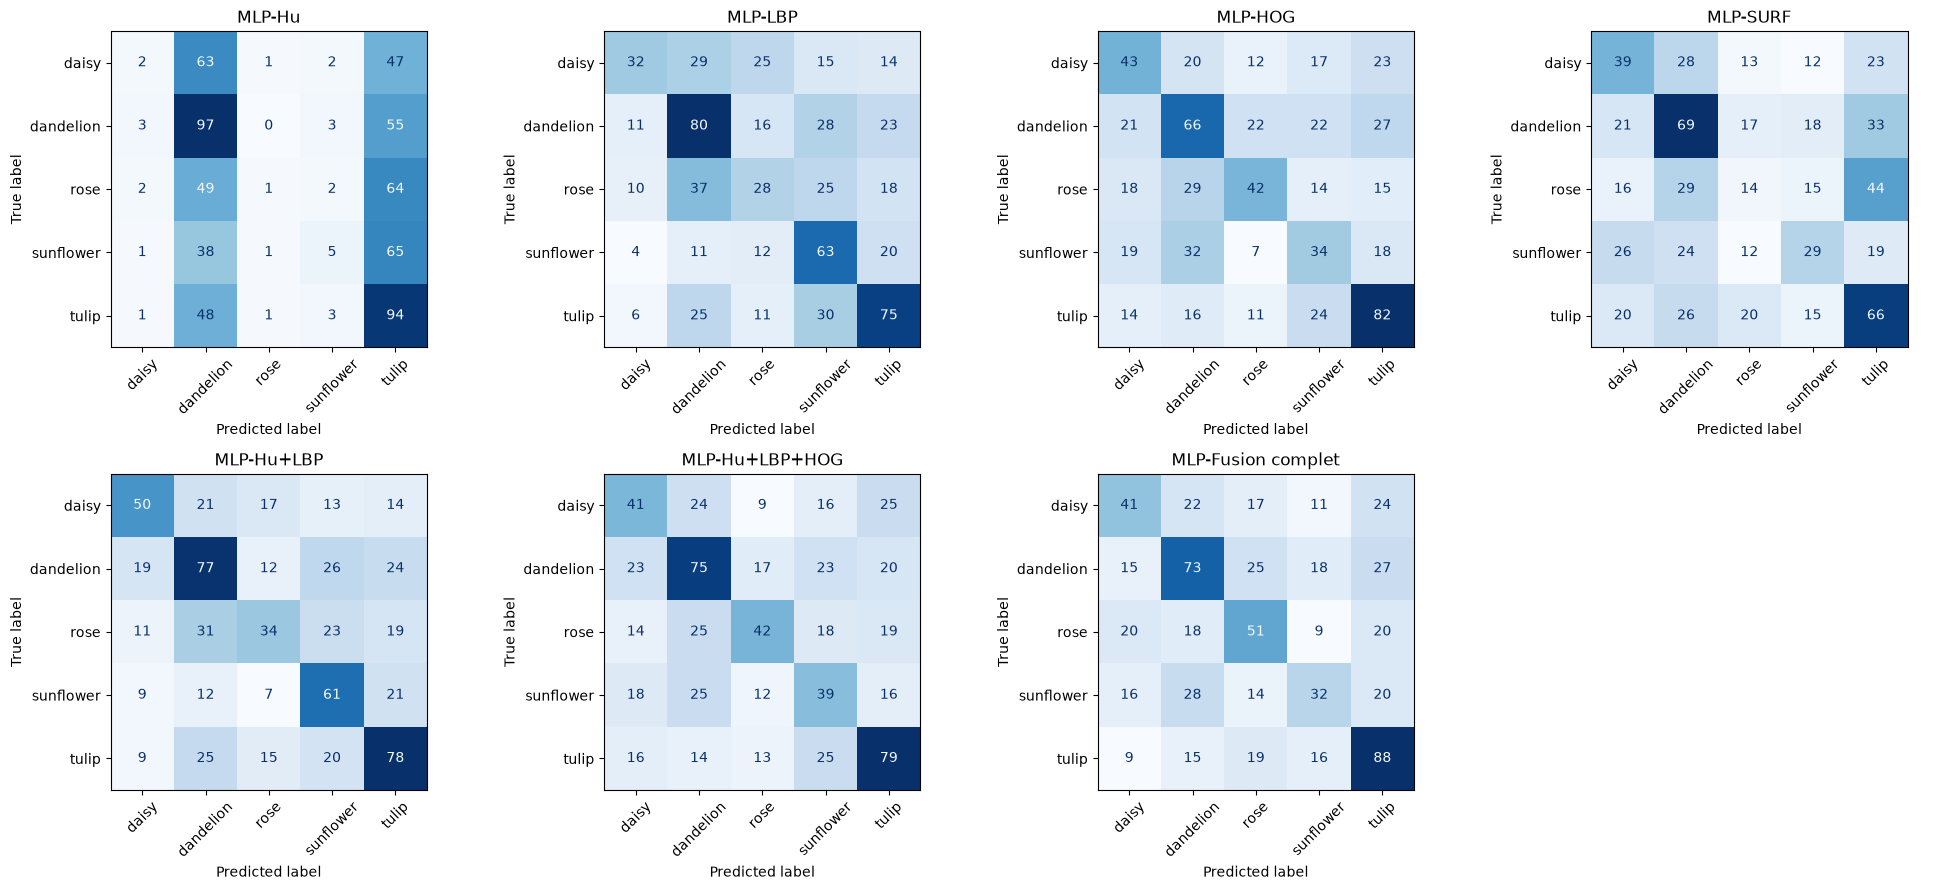

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for ax, (display, key) in zip(axes, final_models.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[key],
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        ax=ax
    )
    ax.set_title(display)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

Rapport détaillé du modèle final (par classe) :

In [33]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    preds["MLP-Fusion complet"],
    target_names=CLASS_NAMES,
    zero_division=0
))

              precision    recall  f1-score   support

       daisy       0.41      0.36      0.38       115
   dandelion       0.47      0.46      0.46       158
        rose       0.40      0.43      0.42       118
   sunflower       0.37      0.29      0.33       110
       tulip       0.49      0.60      0.54       147

    accuracy                           0.44       648
   macro avg       0.43      0.43      0.43       648
weighted avg       0.43      0.44      0.43       648



## 15. Questions d'analyse

1. Quelle est la différence entre une image brute et un vecteur de caractéristiques ?
2. Pourquoi utilise-t-on plusieurs descripteurs pour représenter une même image ?
3. Quelle information est principalement capturée par Hu ?
4. Quelle information est principalement capturée par LBP ?
5. Quelle information est principalement capturée par HOG ?
6. Quelle information est principalement capturée par SURF ?
7. Pourquoi les caractéristiques SURF doivent-elles être transformées avant leur utilisation par le MLP ?
8. Quelle est la différence entre :
   - classification à partir de Hu ;
   - classification à partir de HOG ;
   - classification à partir de la fusion ?
9. Pourquoi faut-il normaliser les caractéristiques avant leur fusion ?
10. La fusion améliore-t-elle systématiquement les performances ?
11. Dans quelles situations un descripteur peut-il être complété par un autre ?
12. Quel modèle obtenez-vous finalement ?

**Réponses :**

*(à compléter)*

## 16. Résultats attendus

| Élément | Résultat attendu |
|---|---|
| Dataset | Split Flowers Recognition rechargé depuis `data/split/` (Train / Val / Test) |
| Hu | Vecteur de 7 caractéristiques par image |
| LBP | Histogramme LBP de 10 caractéristiques par image |
| HOG | Vecteur de caractéristiques basé sur les gradients |
| SURF | Descripteurs locaux SURF transformés en vecteur fixe par BoVW (K = 50) |
| MLP-Hu / LBP / HOG / SURF | Modèles entraînés à partir de chaque famille de caractéristiques |
| Fusion | Concaténation des caractéristiques des quatre descripteurs |
| MLP-Fusion | Nouveau MLP entraîné sur les caractéristiques fusionnées |
| Évaluation | Accuracy, Précision, Rappel, F1-score et matrices de confusion |
| Analyse | Comparaison des représentations individuelles et fusionnées |